<div style="background:#0B1F4B;padding:22px 26px;border-radius:12px;border:3px solid #C9A227;font-family:'Times New Roman',serif">
<img src="https://raw.githubusercontent.com/drssnaiml1-cell/26UAMPC204-Artificial-Intelligence/main/assets/logo.png" alt="Sanjivani University" width="92" style="float:right;background:#FFFFFF;border:2px solid #C9A227;border-radius:8px;padding:3px;margin-left:14px">
<div style="color:#C9A227;font-size:14px;letter-spacing:2px;font-weight:bold">26UAMPC204 · ARTIFICIAL INTELLIGENCE LAB · SANJIVANI UNIVERSITY</div>
<div style="color:#FFFFFF;font-size:30px;font-weight:bold;margin-top:6px">Experiment 1: Uninformed Search — BFS and DFS</div>
<div style="color:#F6EBC8;font-size:15px;margin-top:8px"><b>Course Outcome:</b> CO204.1 &nbsp;|&nbsp; <b>Faculty:</b> Dr. S. Satyanarayana, Professor &amp; Advisor, AI &amp; DS</div>
<div style="clear:both"></div></div>

<div style="background:#F6EBC8;padding:12px 18px;border-radius:8px;margin-top:10px;font-family:'Times New Roman',serif;color:#0B1F4B">
<b>🎯 Aim:</b> Implement Breadth-First Search and Depth-First Search to solve the Water-Jug problem and the 8-puzzle, and compare nodes expanded, path length and memory.</div>

## 📘 Theory

**State space.** A problem is defined by an initial state, actions, a transition model, a goal test and path cost.
**BFS** expands the shallowest node first using a FIFO queue — complete and optimal for unit costs, but needs $O(b^d)$ memory.
**DFS** expands the deepest node first using a LIFO stack — needs only $O(bm)$ memory but is neither complete (in infinite spaces) nor optimal.
**Water-Jug (4 L, 3 L):** state $(x,y)$; actions fill, empty and pour; goal $x=2$.

## 🧭 Algorithm

1. Put the start node in the frontier (queue for BFS / stack for DFS) and mark it reached.
2. Pop a node; if it satisfies the goal test, reconstruct the path through parent links.
3. Otherwise generate successors; push every successor not yet reached and record its parent.
4. Repeat until the goal is found or the frontier is empty.

## ⚙️ Setup

In [1]:
# ---- Course style (navy & gold, Times) -------------------------------------
import os, warnings
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import Image, display

NAVY, NAVY2, GOLD, GOLDL = "#0B1F4B", "#1F3A7A", "#C9A227", "#F6EBC8"
TEAL, CRIMSON, LEAF, MIST, SLATE = "#0E7C86", "#A4243B", "#2E7D32", "#EEF2F8", "#4A5568"
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Liberation Serif", "DejaVu Serif"],
    "axes.edgecolor": SLATE, "axes.titleweight": "bold", "axes.titlecolor": NAVY,
    "axes.titlesize": 14, "axes.labelcolor": NAVY, "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
})
FIG = os.path.join("..", "assets", "figures");    os.makedirs(FIG, exist_ok=True)
ANI = os.path.join("..", "assets", "animations"); os.makedirs(ANI, exist_ok=True)

def save_gif(anim, name, fps=2):
    path = os.path.join(ANI, name)
    anim.save(path, writer=animation.PillowWriter(fps=fps))
    plt.close("all")
    return path
print("Environment ready  ✓  numpy", np.__version__, "| matplotlib", matplotlib.__version__)


Environment ready  ✓  numpy 2.5.3 | matplotlib 3.11.2


## 💻 Implementation and Output

### 1. Water-Jug problem formulation

In [2]:
from collections import deque

CAP = (4, 3)            # jug capacities
START, GOAL_X = (0, 0), 2

def successors(s):
    x, y = s; A, B = CAP
    moves = {
        "Fill 4L":  (A, y), "Fill 3L": (x, B),
        "Empty 4L": (0, y), "Empty 3L": (x, 0),
        "Pour 4→3": (x - min(x, B - y), y + min(x, B - y)),
        "Pour 3→4": (x + min(y, A - x), y - min(y, A - x)),
    }
    return [(a, n) for a, n in moves.items() if n != s]

def is_goal(s): return s[0] == GOAL_X
print("Successors of (0,0):", successors((0, 0)))

Successors of (0,0): [('Fill 4L', (4, 0)), ('Fill 3L', (0, 3))]


### 2. Generic BFS and DFS with statistics

In [3]:
def search(start, succ, goal, strategy="BFS", limit=10**6):
    frontier = deque([start]); parent = {start: (None, None)}
    order, max_frontier = [], 1
    while frontier:
        s = frontier.popleft() if strategy == "BFS" else frontier.pop()
        order.append(s)
        if goal(s):
            path, acts = [s], []
            while parent[path[-1]][0] is not None:
                p, a = parent[path[-1]]; acts.append(a); path.append(p)
            return path[::-1], acts[::-1], order, max_frontier
        for a, n in succ(s):
            if n not in parent:
                parent[n] = (s, a); frontier.append(n)
        max_frontier = max(max_frontier, len(frontier))
        if len(order) > limit: break
    return None, None, order, max_frontier

for strat in ("BFS", "DFS"):
    path, acts, order, mf = search(START, successors, is_goal, strat)
    print(f"\n{strat}: path length = {len(path)-1}, nodes expanded = {len(order)}, max frontier = {mf}")
    for s, a in zip(path, ["Start"] + acts):
        print(f"   {a:<9} → {s}")


BFS: path length = 6, nodes expanded = 13, max frontier = 3
   Start     → (0, 0)
   Fill 4L   → (4, 0)
   Pour 4→3  → (1, 3)
   Empty 3L  → (1, 0)
   Pour 4→3  → (0, 1)
   Fill 4L   → (4, 1)
   Pour 4→3  → (2, 3)

DFS: path length = 6, nodes expanded = 7, max frontier = 3
   Start     → (0, 0)
   Fill 3L   → (0, 3)
   Pour 3→4  → (3, 0)
   Fill 3L   → (3, 3)
   Pour 3→4  → (4, 2)
   Empty 4L  → (0, 2)
   Pour 3→4  → (2, 0)


### 3. Animated BFS over the Water-Jug state space

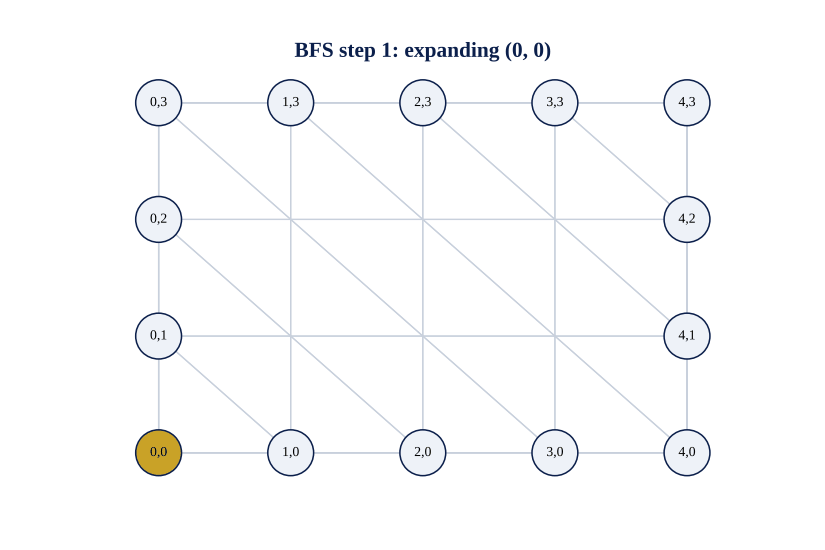

In [4]:
import networkx as nx
G = nx.DiGraph()
for x in range(5):
    for y in range(4):
        for a, n in successors((x, y)): G.add_edge((x, y), n)
reach = nx.descendants(G, START) | {START}
H = G.subgraph(reach)
pos = {n: (n[0] * 1.4, n[1] * 1.2) for n in H.nodes}
_, _, bfs_order, _ = search(START, successors, is_goal, "BFS")

fig, ax = plt.subplots(figsize=(7.5, 5))
def frame(k):
    ax.clear(); seen = set(bfs_order[:k + 1])
    cols = [GOLD if n == bfs_order[k] else (TEAL if n in seen else MIST) for n in H.nodes]
    nx.draw_networkx_edges(H, pos, ax=ax, edge_color="#C8D0DC", arrows=True, arrowsize=8, width=0.8)
    nx.draw_networkx_nodes(H, pos, ax=ax, node_color=cols, edgecolors=NAVY, node_size=900)
    nx.draw_networkx_labels(H, pos, ax=ax, labels={n: f"{n[0]},{n[1]}" for n in H.nodes}, font_size=9, font_family="serif")
    ax.set_title(f"BFS step {k+1}: expanding {bfs_order[k]}", color=NAVY); ax.axis("off")
anim = animation.FuncAnimation(fig, frame, frames=len(bfs_order))
gif = save_gif(anim, "exp01_bfs_waterjug.gif", fps=1.5)
display(Image(filename=gif))

### 4. 8-puzzle with BFS and (depth-limited) DFS

In [5]:
GOAL8 = (1, 2, 3, 4, 5, 6, 7, 8, 0)
def succ8(s):
    i = s.index(0); r, c = divmod(i, 3); out = []
    for a, dr, dc in (("Up", -1, 0), ("Down", 1, 0), ("Left", 0, -1), ("Right", 0, 1)):
        nr, nc = r + dr, c + dc
        if 0 <= nr < 3 and 0 <= nc < 3:
            j = nr * 3 + nc; t = list(s); t[i], t[j] = t[j], t[i]; out.append((a, tuple(t)))
    return out
rng8 = np.random.default_rng(11); start8, prev = GOAL8, None
for _ in range(9):                     # scramble the goal with 9 random non-reversing moves
    opts = [n for a, n in succ8(start8) if n != prev]; prev, start8 = start8, opts[rng8.integers(len(opts))]
print("Start state:", start8)
p, a, o, mf = search(start8, succ8, lambda s: s == GOAL8, "BFS")
print("BFS  : moves =", a, "| expanded =", len(o), "| max frontier =", mf)
p2, a2, o2, mf2 = search(start8, succ8, lambda s: s == GOAL8, "DFS", limit=20000)
print("DFS  :", "gave up after" if p2 is None else f"path length {len(p2)-1},", f"{len(o2):,} expansions (DFS wanders deep — not optimal)")

def show(s, ax, title):
    ax.imshow(np.zeros((3, 3)), cmap="Greys", vmin=0, vmax=1)
    for k, v in enumerate(s):
        r, c = divmod(k, 3)
        ax.add_patch(plt.Rectangle((c - .45, r - .45), .9, .9, color=NAVY if v else "white", ec=GOLD, lw=2))
        if v: ax.text(c, r, v, ha="center", va="center", color=GOLD, fontsize=20, weight="bold")
    ax.set_title(title, fontsize=11); ax.axis("off")
fig, axs = plt.subplots(1, len(p), figsize=(2.1 * len(p), 2.4))
for ax, s, t in zip(axs, p, ["Start"] + a): show(s, ax, t)
plt.tight_layout(); plt.savefig(f"{FIG}/exp01_8puzzle_path.png", dpi=130); plt.show()

Start state: (4, 1, 2, 7, 5, 0, 8, 6, 3)
BFS  : moves = ['Down', 'Left', 'Left', 'Up', 'Up', 'Right', 'Right', 'Down', 'Down'] | expanded = 390 | max frontier = 231
DFS  : path length 319, 326 expansions (DFS wanders deep — not optimal)


### 5. Comparison

In [6]:
import pandas as pd
rows = []
for strat in ("BFS", "DFS"):
    pth, _, od, mfr = search(START, successors, is_goal, strat)
    rows.append([strat, len(pth) - 1, len(od), mfr])
df = pd.DataFrame(rows, columns=["Strategy", "Path length", "Nodes expanded", "Max frontier"])
print(df.to_string(index=False))
ax = df.set_index("Strategy")[["Path length", "Nodes expanded", "Max frontier"]].plot.bar(color=[NAVY, GOLD, TEAL], figsize=(6, 3.5), rot=0)
ax.set_title("Water-Jug: BFS vs DFS"); plt.tight_layout(); plt.savefig(f"{FIG}/exp01_compare.png", dpi=130); plt.show()

Strategy  Path length  Nodes expanded  Max frontier
     BFS            6              13             3
     DFS            6               7             3


## ✅ Result and Conclusion

<div style="border-left:6px solid #2E7D32;background:#E3F2E4;padding:12px 18px;border-radius:6px;font-family:'Times New Roman',serif;color:#1A202C">
<b style="color:#2E7D32">Conclusion</b><br>Both strategies solved the Water-Jug problem in 6 moves, but only BFS guarantees the shortest solution. On the scrambled 8-puzzle BFS found the optimal path while DFS wandered thousands of nodes deep without returning a short solution. BFS suits shallow solutions; DFS suits tight memory.</div>

## 🎤 Viva Questions

1. Why is BFS optimal only when all step costs are equal?
2. What is the space complexity of DFS and why is it smaller than BFS?
3. How do you detect that an 8-puzzle state is unsolvable?
4. What is the difference between tree search and graph search?
5. Why does the Water-Jug state graph contain cycles?